In [24]:
import numpy as np
from numba import jit, njit, prange
import time
import numba
import matplotlib.pyplot as plt

In [2]:
print(numba.config.NUMBA_NUM_THREADS)  # verfügbare Threads

28


# Introduction
Testing various numba functionalities and conducting performance measurements.

In [3]:
# Various versions of the sum function

@njit
def numba_summe_quadrate(x):
    s = 0.0
    for v in x:
        s += v * v
    return s

@njit(parallel=True)
def par_summe_quadrate(x):
    s = 0.0
    for i in prange(len(x)):
        s += x[i] * x[i]
    return s

def py_summe_quadrate(x):
    s = 0.0
    for v in x:
        s += v * v
    return s

In [4]:
# Values
vals = np.random.rand(1_000_000)

In [5]:
# Warmup non parallelized numba version
t1 = time.perf_counter()
numba_summe_quadrate(vals)
t2 = time.perf_counter()
print(f"Compile time non-parallized version: {t2-t1:.4f}.")

Compile time: 0.1120.


In [6]:
# Warmup parallelized numba version
t1 = time.perf_counter()
par_summe_quadrate(vals)
t2 = time.perf_counter()
print(f"Compile time parallelized version: {t2-t1:.4f}.")

Compile time parallelized version: 0.1914.


In [7]:
# Sanity check
assert np.allclose(numba_summe_quadrate(vals), py_summe_quadrate(vals))
assert np.allclose(numba_summe_quadrate(vals), par_summe_quadrate(vals))

In [8]:
# Numba non-parallelized performance
%timeit -n 100 -r 3 numba_summe_quadrate(vals)

378 μs ± 8.43 μs per loop (mean ± std. dev. of 3 runs, 100 loops each)


In [9]:
# Python version
%timeit -n 100 -r 3 py_summe_quadrate(vals)

55.8 ms ± 435 μs per loop (mean ± std. dev. of 3 runs, 100 loops each)


In [10]:
# Numba parallel version
%timeit -n 100 -r 3 par_summe_quadrate(vals)

71.7 μs ± 16.3 μs per loop (mean ± std. dev. of 3 runs, 100 loops each)


In [12]:
# Numpy version
%timeit -n 100 -r 3 (vals * vals).sum()

430 μs ± 51.5 μs per loop (mean ± std. dev. of 3 runs, 100 loops each)


# Visualisierungen
Hier eine visualisierte Version der Ergebnisse.

In [18]:
results = {}

In [20]:
# Save results in dict
results["numba_results"] = %timeit -o -q -n 100 -r 3 numba_summe_quadrate(vals)
results["py_results"] = %timeit -o -q -n 100 -r 3 py_summe_quadrate(vals)
results["par_results"] = %timeit -o -q -n 100 -r 3 par_summe_quadrate(vals)
results["np_results"] = %timeit -o -q -n 100 -r 3 (vals * vals).sum()

In [21]:
results

{'numba_results': <TimeitResult : 374 μs ± 4.81 μs per loop (mean ± std. dev. of 3 runs, 100 loops each)>,
 'py_results': <TimeitResult : 55 ms ± 584 μs per loop (mean ± std. dev. of 3 runs, 100 loops each)>,
 'par_results': <TimeitResult : 61.9 μs ± 5.31 μs per loop (mean ± std. dev. of 3 runs, 100 loops each)>,
 'np_results': <TimeitResult : 375 μs ± 5.48 μs per loop (mean ± std. dev. of 3 runs, 100 loops each)>}

In [28]:
def plot_vergleich(ergebnisse, referenz=None, titel="Laufzeitvergleich"):
    namen = list(ergebnisse)
    zeiten = np.array([r.average for r in ergebnisse.values()])
    fehler = np.array([r.stdev for r in ergebnisse.values()])
    referenz = referenz or namen[0]
    t_ref = ergebnisse[referenz].average

    farben = plt.cm.viridis(np.linspace(0.15, 0.85, len(namen)))

    fig, ax = plt.subplots(figsize=(8, 5))
    balken = ax.bar(namen, zeiten, yerr=fehler, capsize=5,
                    color=farben, edgecolor="black", linewidth=0.8)

    ax.set_yscale("log")                      # Unterschiede über Größenordnungen
    ax.set_ylabel("Zeit pro Aufruf [s]")
    ax.set_title(titel)
    ax.grid(axis="y", which="both", alpha=0.3)
    ax.set_axisbelow(True)
    ax.set_ylim(top=(zeiten + fehler).max() * 5)

    for b, t in zip(balken, zeiten):
        speedup = t_ref / t
        ax.annotate(f"{t*1e3:.2f} ms\n({speedup:.1f}x)",
                    (b.get_x() + b.get_width() / 2, t),
                    ha="center", va="bottom",
                    xytext=(0, 6), textcoords="offset points", fontsize=9)

    ax.spines[["top", "right"]].set_visible(False)
    plt.tight_layout()
    plt.show()

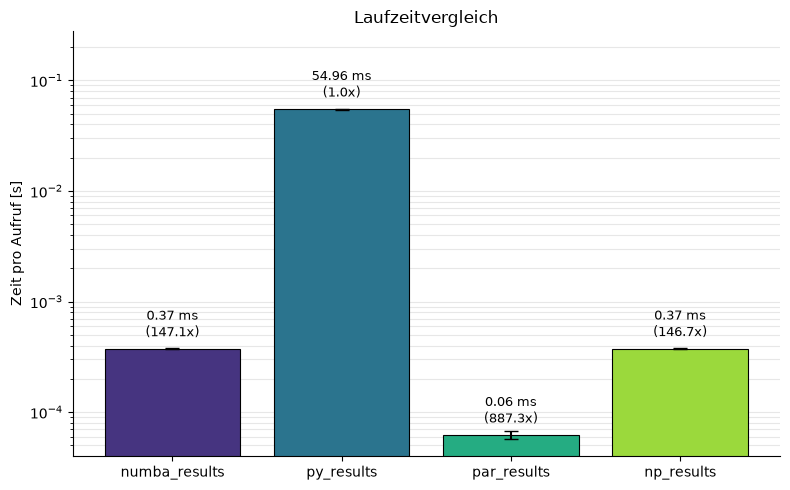

In [29]:
plot_vergleich(results, referenz="py_results")